# 4.2. Images as Multidimensional Arrays

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

## Previous lesson review

Warm-up: *Check yourself 4.2 - NumPy*



## Today

1. **Why images?** - the 3D array you can *see*
2. **PIL** - opening an image; the image as a NumPy array (shape, dtype, pixels)
3. **Slicing and copying** - cropping, the view trap again
4. **Changes** - mirror, flip, rotate, threshold
5. **Colours** - channels, re-ordering, inverting, reducing, brightness, grayscale
6. **Image kernels** - blur and outline filters


## Why images?

Everything from 4.1 - shape, slicing, masks, `axis`, broadcasting, `.copy()` - becomes **visible** on an image: a wrong slice is a wrong crop, a mask is a black-and-white picture, `axis=2` is "the colours". That is why we practise NumPy on pictures.

And images *are* data: medical scans, satellite photos, scanned documents, camera feeds in traffic analysis, every photo in a social network. Computer vision starts exactly here - with a picture as an array of numbers.

An image is a 3D array: rows (height) × columns (width) × 3 colour channels
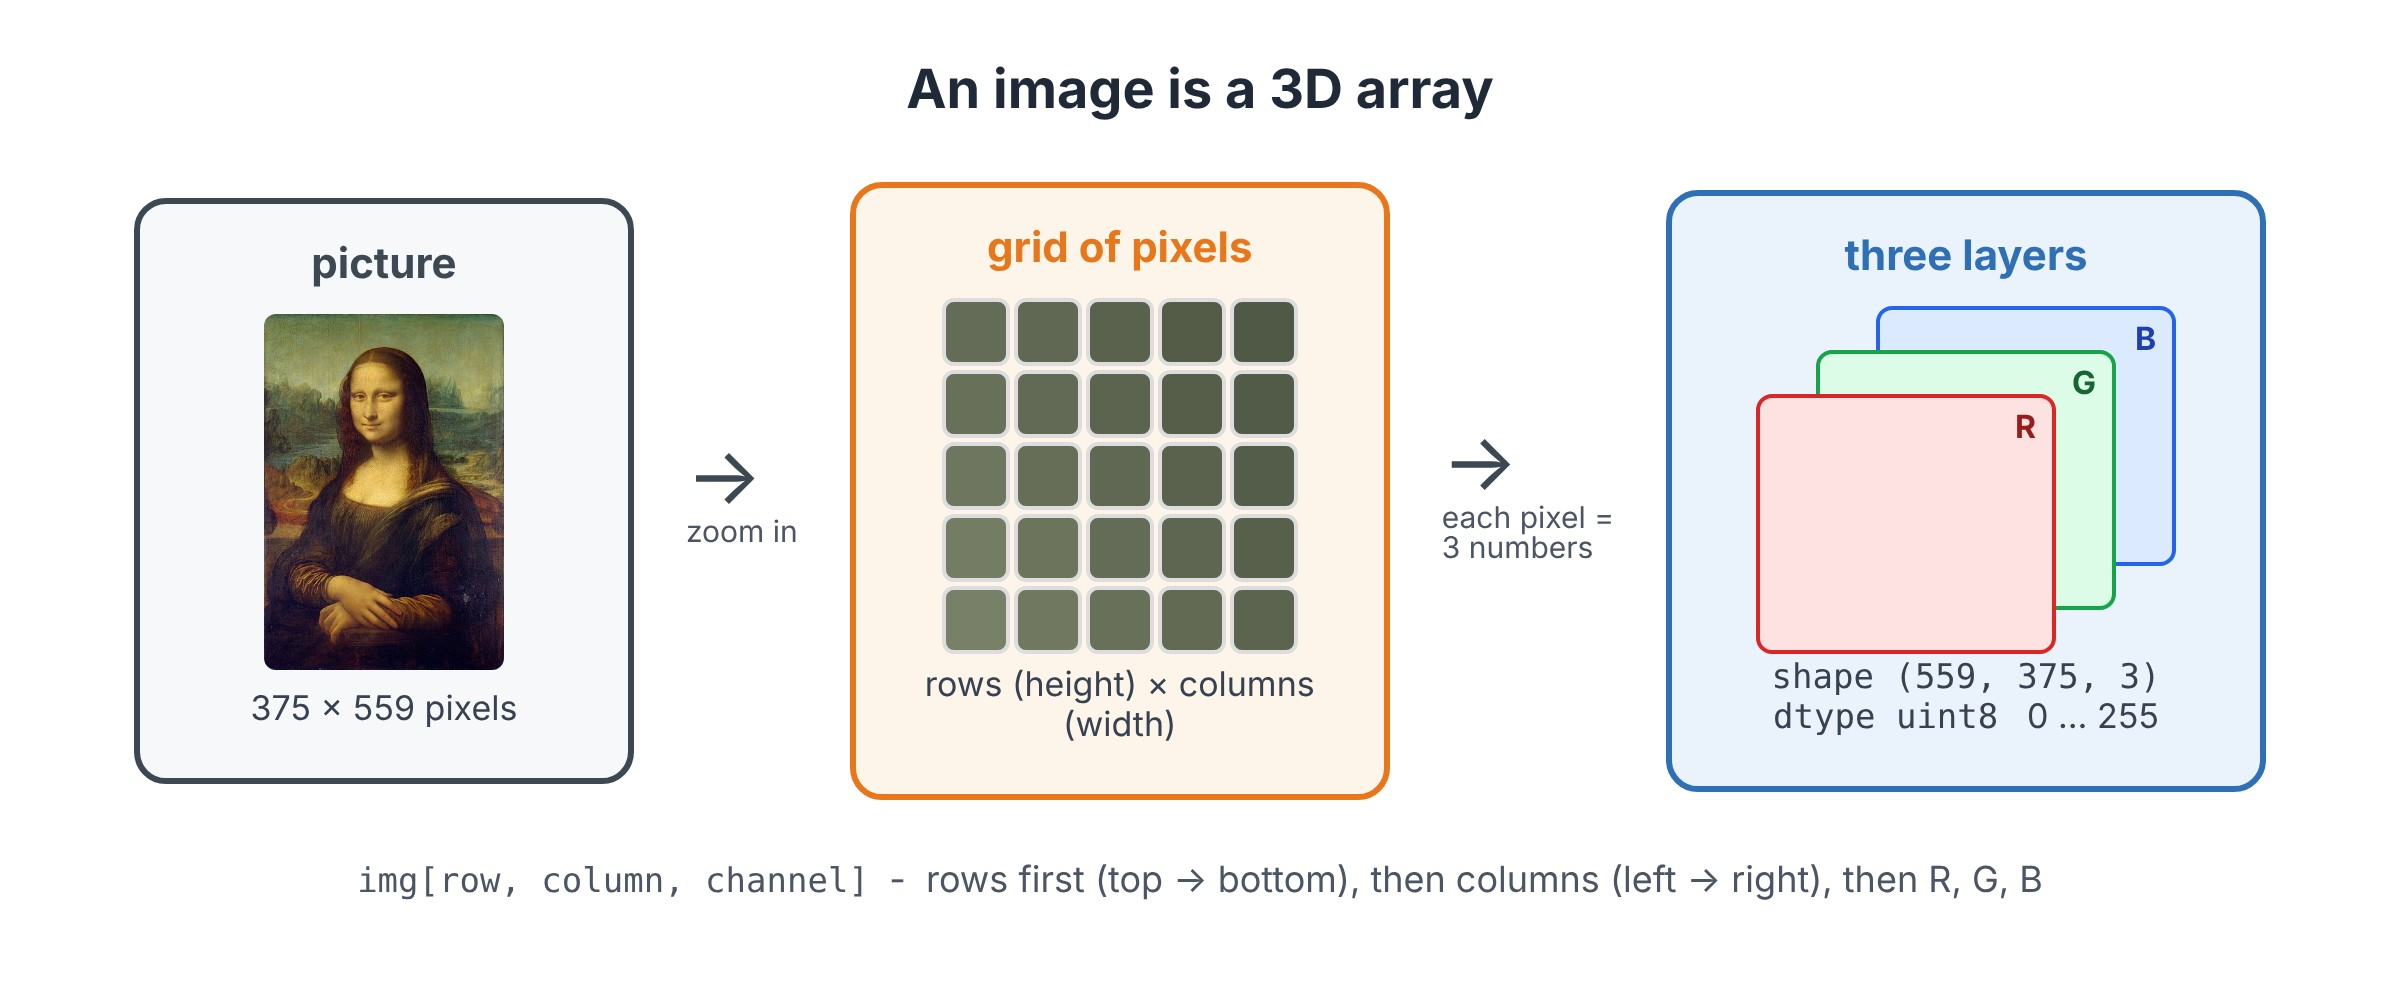

## PIL library

Python Imaging Library (PIL) is a free and open-source additional library for the Python programming language that adds support for opening, manipulating, and saving many different image file formats.

Today the library is called **Pillow** (`pip install pillow`), but it is still imported as `PIL` - a small historical confusion to remember. It is already installed in Google Colab. First we need the picture in our working folder:

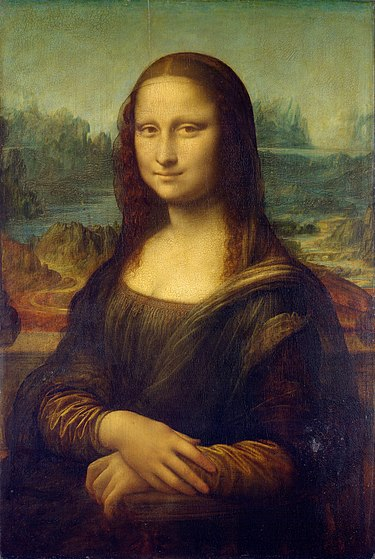

In [1]:
from PIL import Image
lisa_img = Image.open('Mona_Lisa.jpg')
lisa_img

A PIL image object knows its size, colour mode and file format. Note: PIL reports **width × height** - NumPy will report rows × columns, i.e. the other way round.

In [2]:
print(lisa_img.size)        # (width, height) in pixels
print(lisa_img.mode)        # RGB = three colour channels
print(lisa_img.format)

(375, 559)
RGB
JPEG


## Images as 3D arrays

Images are naturally 3D array - 2D array of pixel values (0-255) for every channel (e.g., RGB - Red, Green, Blue channels)

`np.asarray()` turns the image into a NumPy array; `.copy()` makes sure we own the data (PIL's version is read-only). The shape reads: **559 rows, 375 columns, 3 channels**.

In [45]:
import numpy as np
lisa_arr = np.asarray(lisa_img).copy()
lisa_arr.shape

(559, 375, 3)

In [4]:
print(lisa_arr.dtype)                     # uint8: whole numbers 0 ... 255
print(lisa_arr.ndim, lisa_arr.size)       # 3 dimensions, 559 * 375 * 3 numbers
print(lisa_arr.min(), lisa_arr.max())

uint8
3 628875
0 255


* First pixel

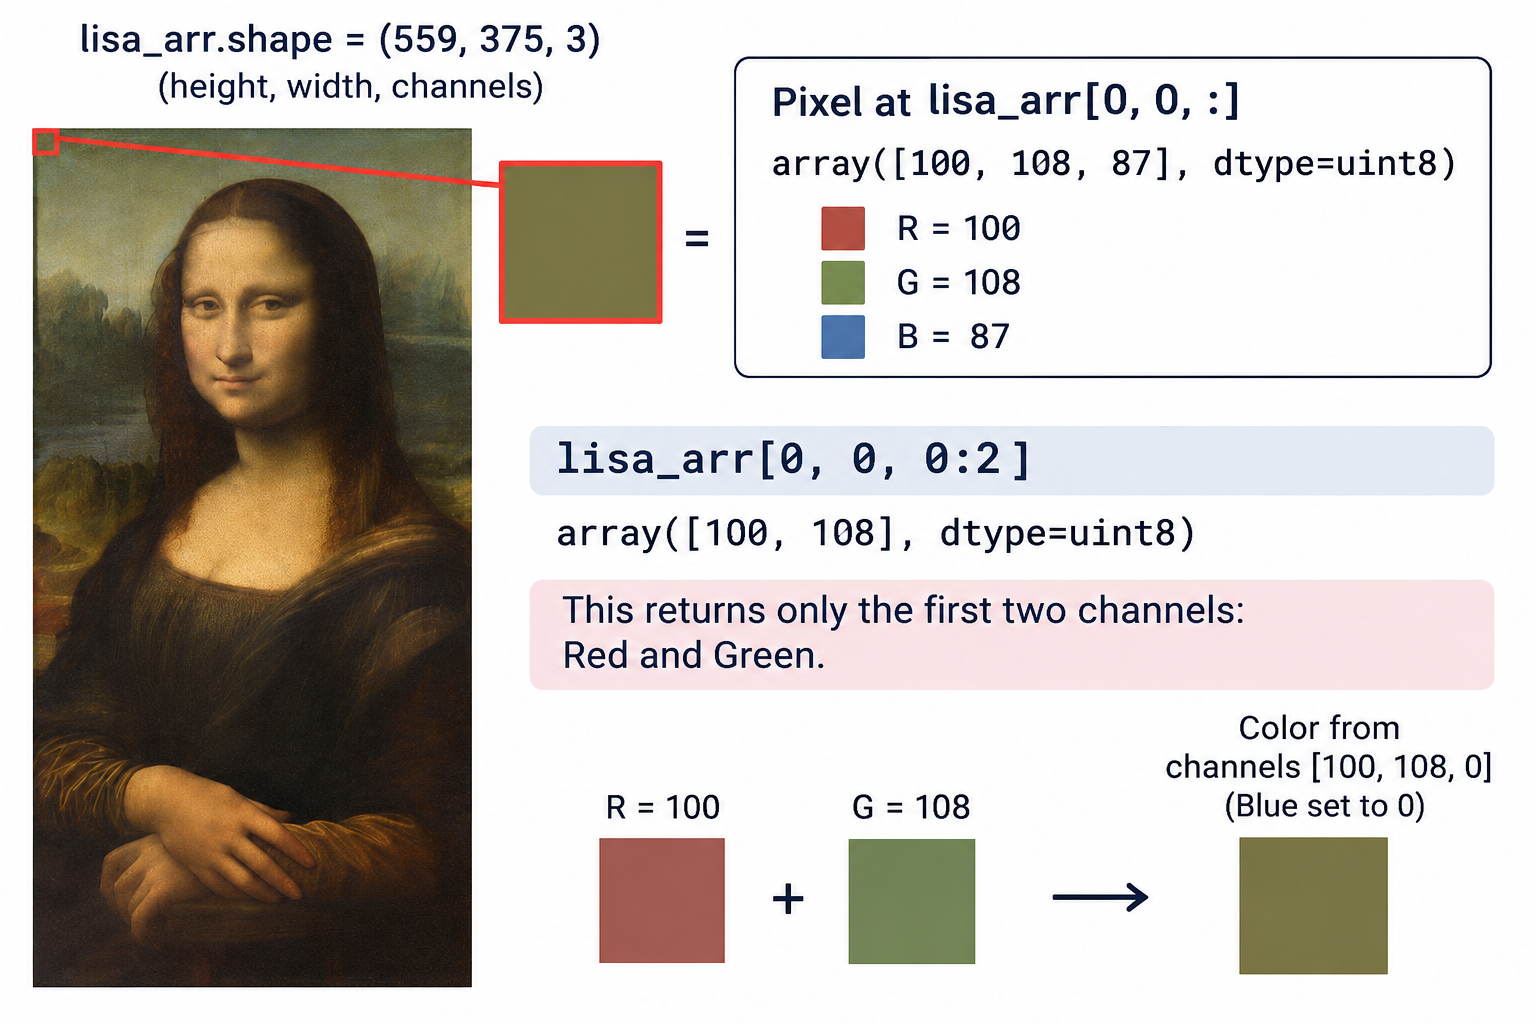

lisa_arr[0, 0, :]
- the 1st 0 is height (row).
- the 2nd 0 is width (column).
- : is all channels (R, G, B).

In [70]:
lisa_arr[0,0,:]

array([100, 108,  87], dtype=uint8)

* Get only the first two channels

In [69]:
lisa_arr[0,0,0:2]

array([100, 108], dtype=uint8)

The first pixel (top-left corner) is `[100, 108, 87]` - a bit of everything, slightly more green: a dark olive. `Image.fromarray` turns an array back into a picture, so we can look at a single colour by filling a small array with it:

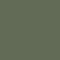

In [79]:
swatch = np.zeros((60, 60, 3), dtype=np.uint8)
swatch[:, :] = lisa_arr[0, 1, :]            # broadcasting: one pixel -> every cell
Image.fromarray(swatch)

### YOUR TURN 1: explore the image

1. Print the pixel in the centre of the image (row 279, column 187). What are its three numbers?
2. Show the first pixel [0, 0] and the centre pixel [279, 187] as two colour strips, one under the other:
- create an empty np.zeros((30, 300, 3), dtype=np.uint8) array (30 rows × 300 columns),
- fill it with the pixel’s colour,
- show it with display(Image.fromarray(...)).
- Print a label before each strip.

Which strip is brighter — the corner (background) or the centre (the face)?


In [ ]:
# YOUR CODE HERE:

In [96]:
# 1.
print(lisa_arr[279, 187])

# 2 The first pixel
print("The first pixel:")
swatch = np.zeros((30, 300, 3), dtype=np.uint8)
swatch[:, :] = lisa_arr[0, 0, :]
display(Image.fromarray(swatch))

# 2 The centre pixel
print("The centre pixel:")
second = np.zeros((30, 300, 3), dtype=np.uint8)
second[:, :] = lisa_arr[279, 187, :]
display(Image.fromarray(second))

[226 191 101]
The first pixel:


The centre pixel:


## Slicing / Copy

Cropping is slicing: rows 100-199 (vertical), columns 130-219 (horizontal), all channels. We immediately make a **copy** too - we will need an untouched face later.

Rows first (top to bottom), then columns (left to right) - like reading a table, not like x / y on a graph
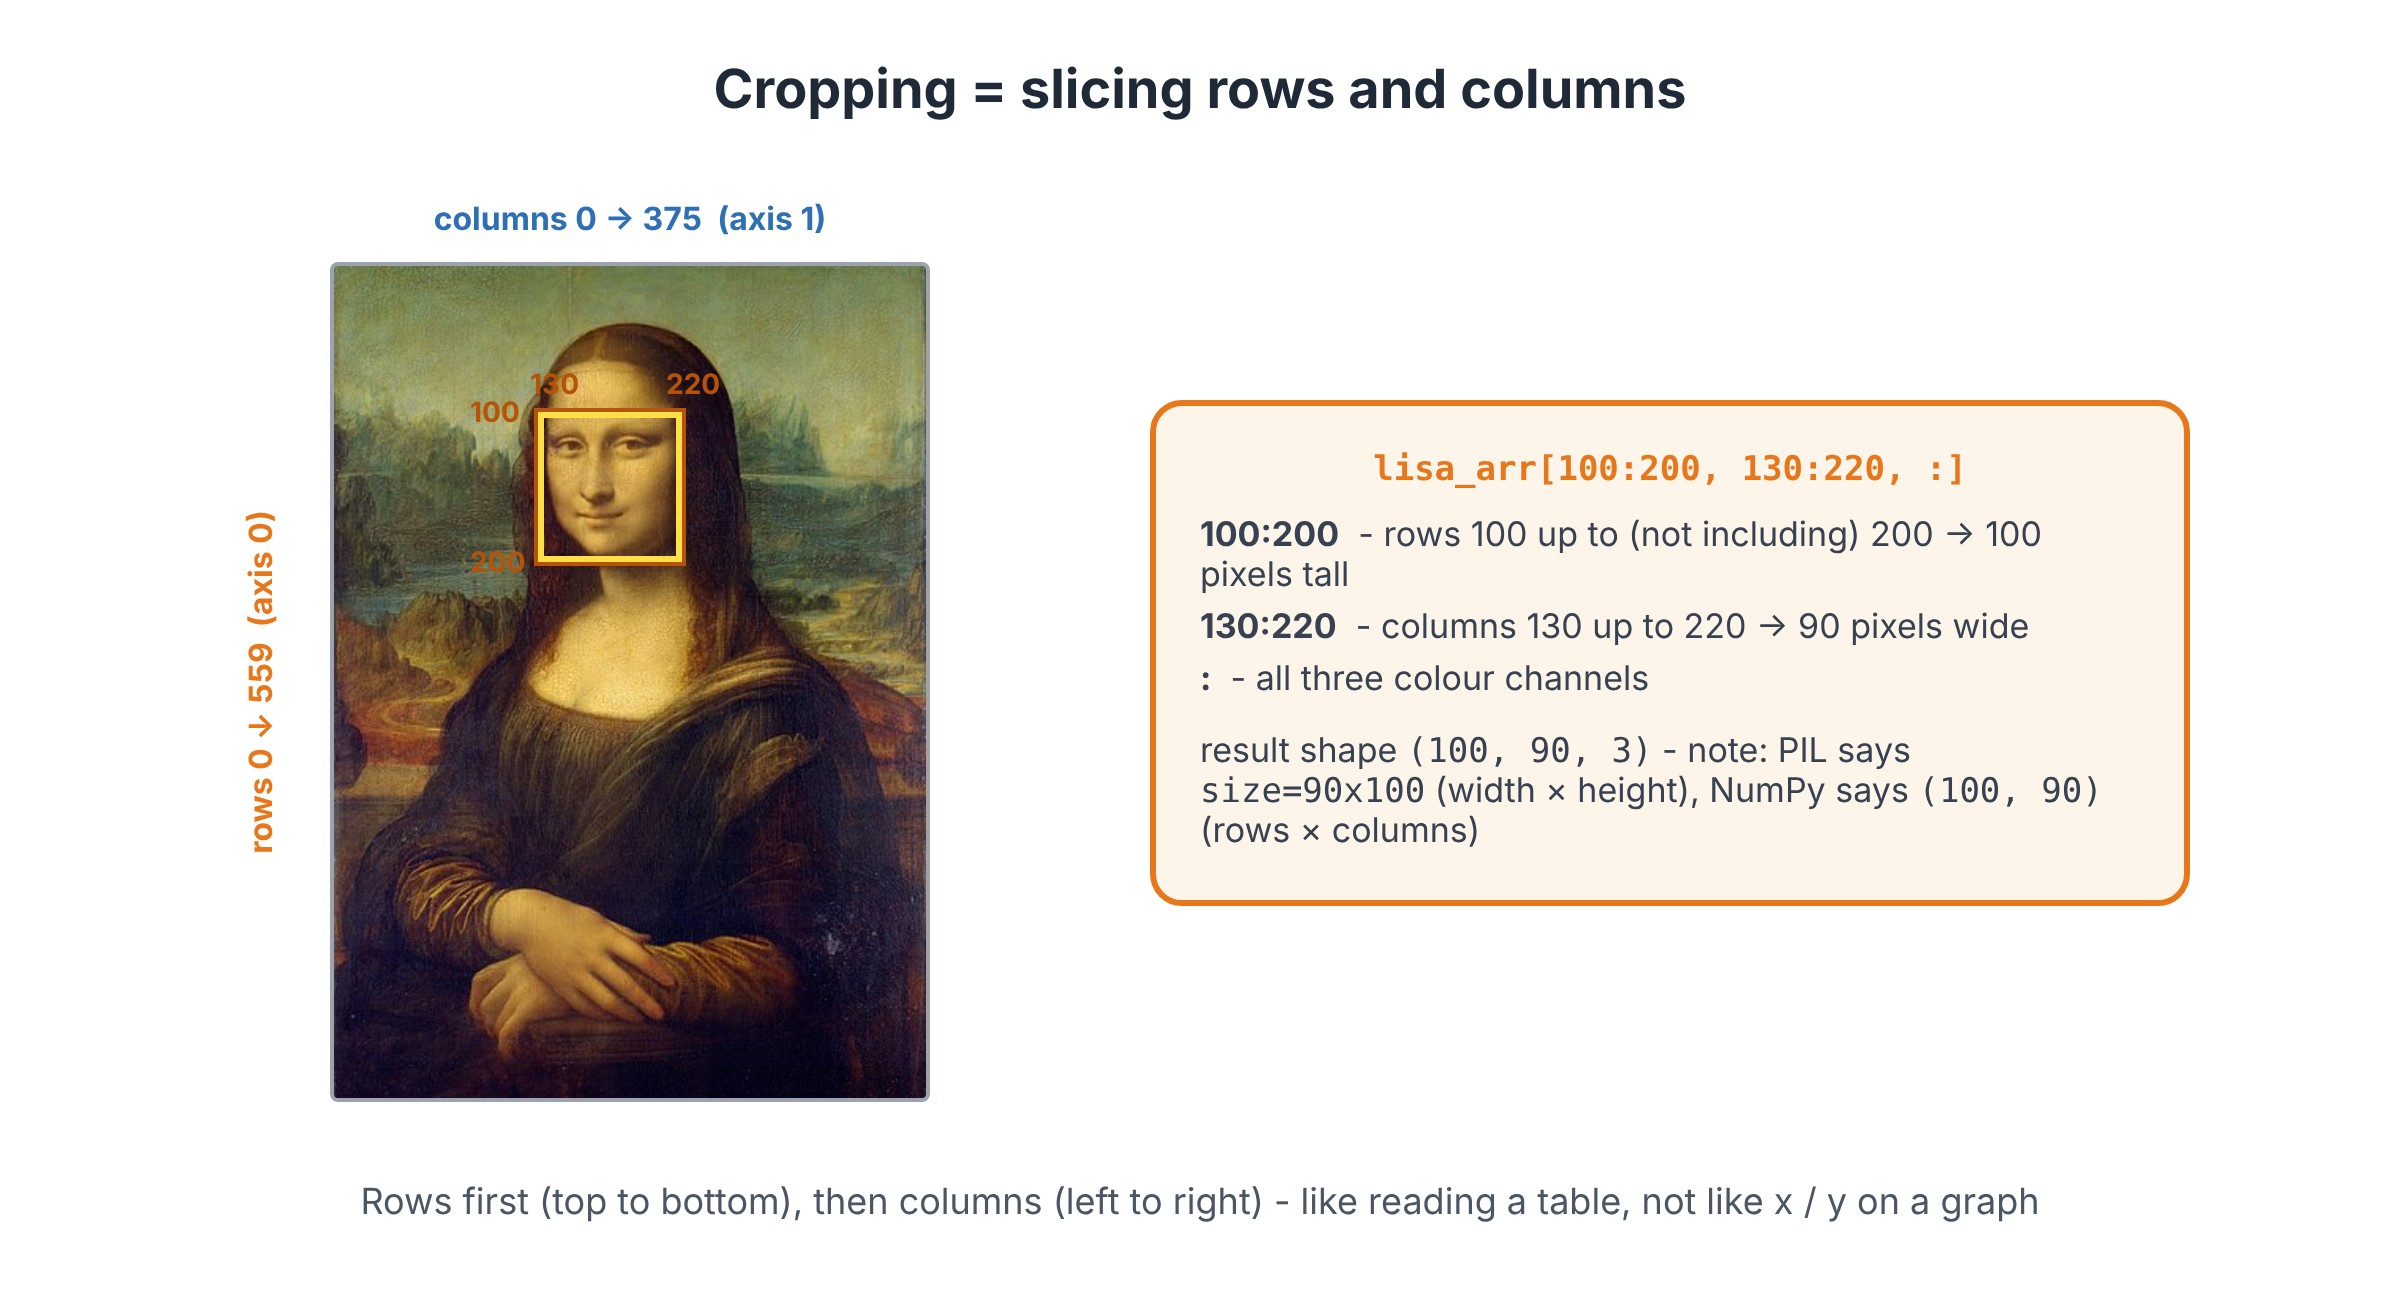

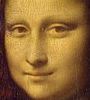

In [112]:
lisa_face = lisa_arr[100:200,130:220,:]
lisa_face_copy = lisa_face.copy()
Image.fromarray(lisa_face)

One channel only - `[:, :, 1]` is the **green** layer, a 2D array of 100 × 90 numbers. PIL shows a 2D array as a grayscale picture (mode `L`): 0 = black, 255 = white.

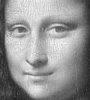

In [116]:
Image.fromarray(lisa_face[:,:,1])

In [117]:
print(lisa_face.shape, lisa_face[:, :, 1].shape)

(100, 90, 3) (100, 90)


## Changes

`::-1` on the **columns** reverses them - a mirror image (here of the green channel):

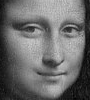

In [29]:
Image.fromarray(lisa_face[:,::-1,1])

### YOUR TURN 2: crops and flips

1. Crop the **hands** - rows 400-529, columns 60-309 - into `hands` (as a copy) and show them. What is the shape?
2. Show the hands mirrored (left ↔ right).

(130, 250, 3)


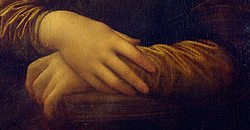

In [144]:
# 1.
hands = lisa_arr[400:530, 60:310].copy()
print(hands.shape)
Image.fromarray(hands)

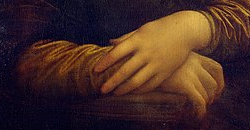

In [145]:
# 2.
Image.fromarray(hands[:, ::-1])

A mask works on an image as on any array: `lisa_face > 100` is `True` for every channel value above 100; those values are set to 255 (full brightness) - a crude "high-contrast" effect:

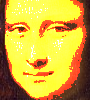

In [123]:
lisa_face = lisa_arr[100:200,130:220,:]
lisa_face[lisa_face>100] = 255
Image.fromarray(lisa_face)

### Slicing is a view, not a copy!

We changed `lisa_face` ... and the **whole painting** changed with it - `lisa_face` was a slice, i.e. a window onto `lisa_arr`. This is the 4.1 rule again, now visible:

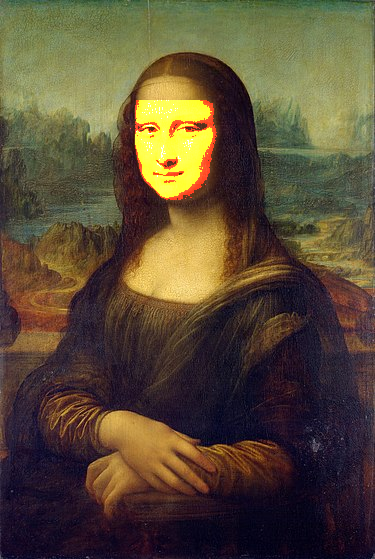

In [124]:
Image.fromarray(lisa_arr)

From here on we work on `lisa_face_copy` - the untouched copy we made in time. Let us also restore the painting itself from the file:

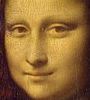

In [126]:
lisa_arr = np.asarray(Image.open('Mona_Lisa.jpg')).copy()
lisa_face = lisa_face_copy.copy()
Image.fromarray(lisa_arr[100:200, 130:220])

### YOUR TURN 3:
* Display the original hands image from the previous exercise.
* Create an independent copy of hands called hands2.
* In hands2, replace all pixel channel values greater than 100 with 0.
Display the modified image and compare it with the original. What has changed?

Original:


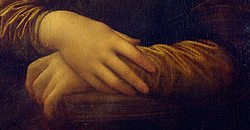

Modified hands:


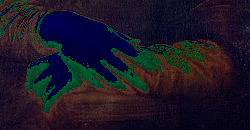

In [150]:

# 1
print("Original:")
display(Image.fromarray(hands))

#2
hands2 = hands.copy()
hands2[hands2>100] = 0
print("Modified hands:")
display(Image.fromarray(hands2))



### Flipping and rotating

Reversing rows flips the picture upside down, reversing columns mirrors it; swapping the row and column axes (transposition - `np.transpose` with the channel axis kept last) rotates it. NumPy also has ready-made `np.flipud`, `np.fliplr` and `np.rot90`.

A step of -1 walks backwards; for a colour image the third index (channels) always stays ':'
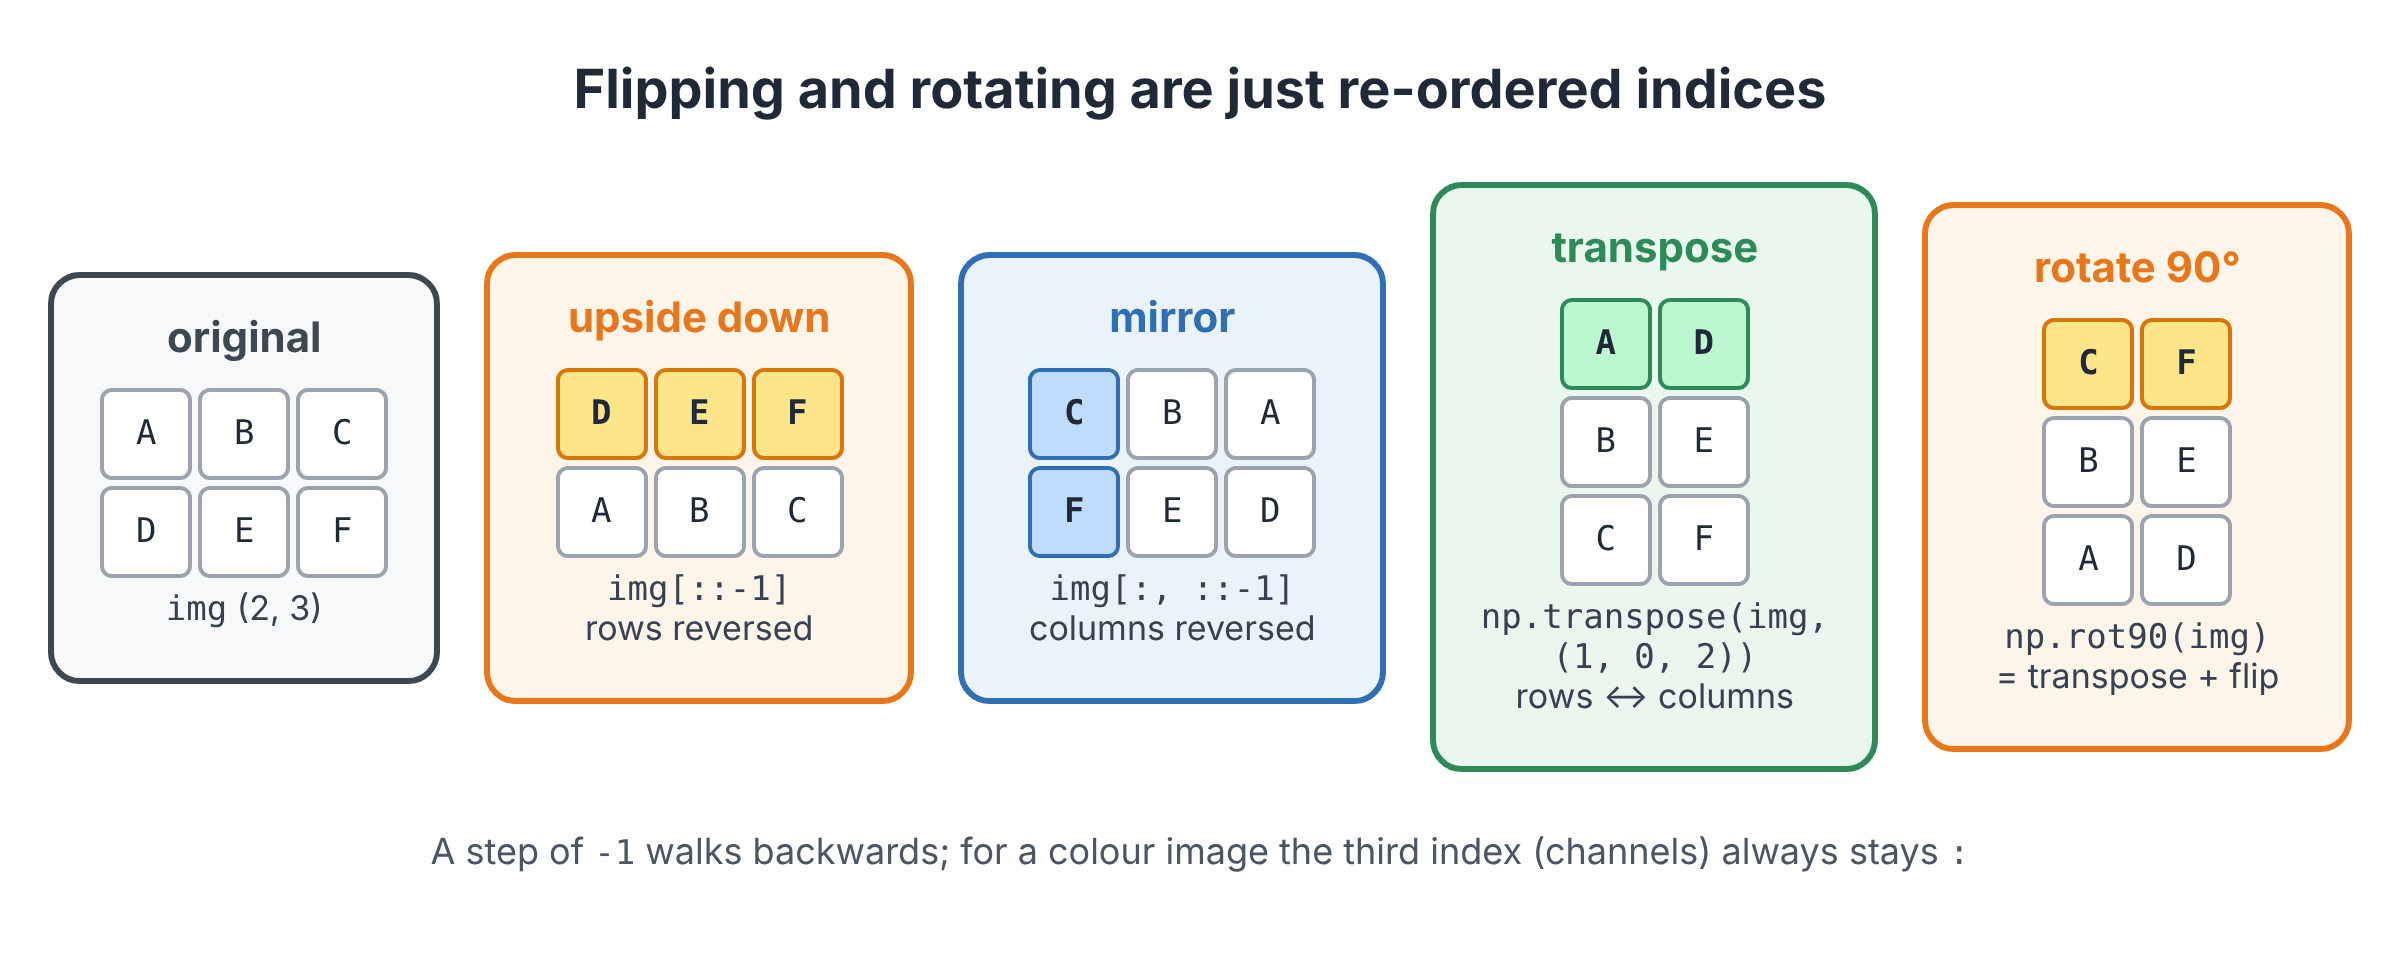

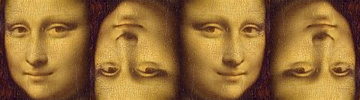

In [152]:
upside_down = lisa_face_copy[::-1]                       # rows reversed
mirror      = lisa_face_copy[:, ::-1]                    # columns reversed
both        = lisa_face_copy[::-1, ::-1]                 # = rotated by 180 degrees
Image.fromarray(np.concatenate((lisa_face_copy, upside_down, mirror, both), axis=1))

(100, 90, 3) -> (90, 100, 3)


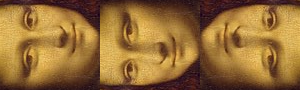

In [34]:
rotated = np.transpose(lisa_face_copy, (1, 0, 2))        # rows <-> columns, channels stay last
print(lisa_face_copy.shape, "->", rotated.shape)
Image.fromarray(np.concatenate((rotated, np.rot90(lisa_face_copy), np.rot90(lisa_face_copy, k=3)), axis=1))

### YOUR TURN 4: crops and flips
Use the original hands image from the previous exercise.
* Create an upside-down version by reversing the rows.
* Create a mirrored version by reversing the columns.
* Create a version flipped both vertically and horizontally.
* Combine all four images horizontally using np.concatenate() and display the result.


In [ ]:
# YOUR CODE HERE:

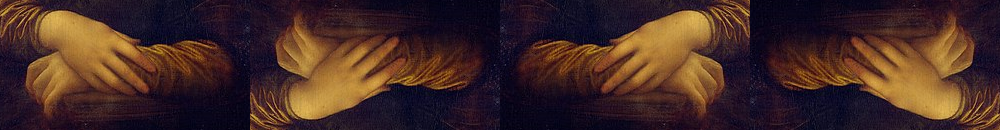

In [156]:
#1 Reverse rows
upside_down = hands[::-1]

# Reverse columns
mirror = hands[:, ::-1]

# Rotate 180 degrees
both = hands[::-1, ::-1]

# Display all four images side by side
result = np.concatenate((hands, upside_down, mirror, both), axis=1)

display(Image.fromarray(result))

### Separating channels

To see one colour we keep its channel and set the other two to 0. `im_R[:, :, [1, 2]] = 0` is fancy indexing on the channel axis: channels 1 (green) and 2 (blue) become zero, only red remains.

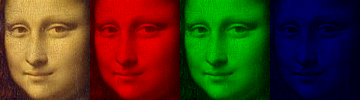

In [159]:
im_R = lisa_face_copy.copy()
im_R[:, :, [1, 2]] = 0
im_G = lisa_face_copy.copy()
im_G[:, :, [0, 2]] = 0
im_B = lisa_face_copy.copy()
im_B[:, :, [0, 1]] = 0

im_RGB = np.concatenate((lisa_face_copy, im_R, im_G, im_B), axis=1)
Image.fromarray(im_RGB)

### Re-ordering channels (fancy indexing)

A tuple of channel positions `(2, 1, 0)` picks the channels in a new order: blue becomes red and red becomes blue - the painting turns cold.

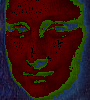

In [167]:
Image.fromarray(lisa_face[:,:,(2,1,0)])

### Inverting channels

`255 - array` is broadcasting with a number: every value is subtracted from 255, dark becomes bright and every colour becomes its opposite - a photographic negative.

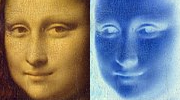

In [176]:
im_i = 255-lisa_face_copy
Image.fromarray(np.concatenate((lisa_face_copy, im_i), axis=1))

### Reducing colours

Integer division then multiplication: `// 32 * 32` rounds every value **down** to a multiple of 32 (0, 32, 64, ... 224) - only 8 levels per channel instead of 256, so 8³ = 512 colours instead of 16 million. The effect is called *posterisation*.

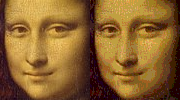

In [177]:
im_i = lisa_face_copy // 32 * 32
Image.fromarray(np.concatenate((lisa_face_copy, im_i), axis=1))



```
# This is formatted as code
```

## Image kernels

Blur, sharpen, edge detection - the classic photo filters - are all the **same operation** with different numbers: a small table of weights (the *kernel*) slides over the picture, and every output pixel is the weighted sum of its 3×3 neighbourhood. (Convolutional neural networks *learn* such kernels - this is where deep learning for images starts.)

A kernel is a 3×3 table of weights: each output pixel is the weighted sum of its neighbourhood
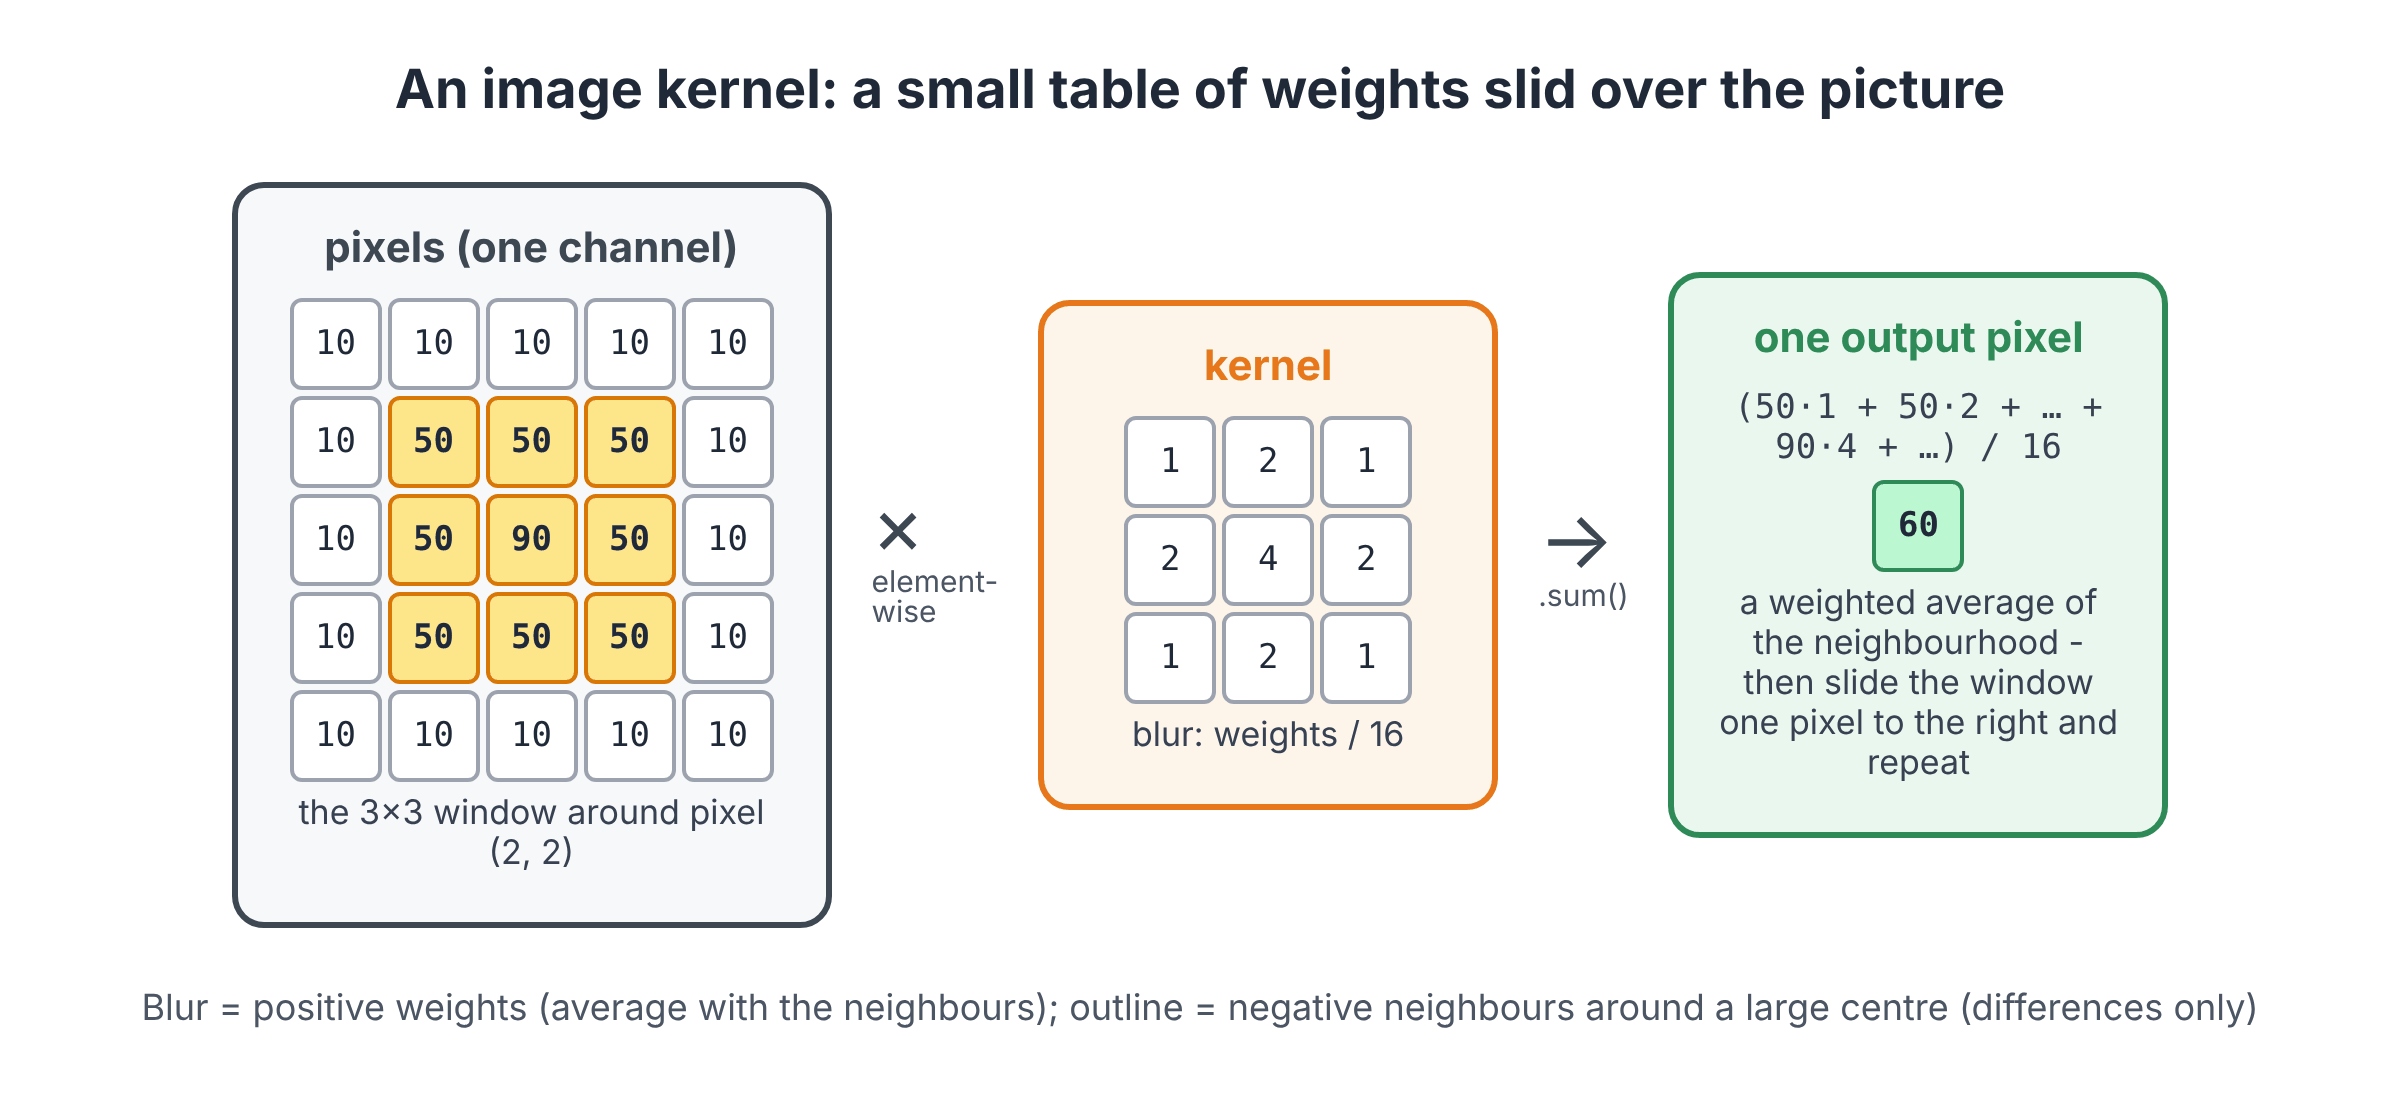

The function below does exactly the picture: for every row, column and channel it takes the 3×3 window (`arr[row:row+3, col:col+3, ch]`), multiplies it element-wise by the kernel, sums, and writes the result to the output pixel. Three nested loops - slow in Python, which is why real libraries (SciPy, OpenCV) do it in C. On a 100×90 face it is fast enough.

The function moves a small kernel across an image. At each position, it multiplies neighbouring pixel values by the kernel coefficients, adds the results, and stores the new pixel value in the output image. This process is repeated for every colour channel.

In [184]:
def apply_kernel(arr, kernel):
    res = np.zeros_like(arr)
    for row in range(arr.shape[0]-kernel.shape[0]):
        for col in range(arr.shape[1]-kernel.shape[1]):
            for ch in range(arr.shape[2]):
                res[row+int(kernel.shape[0]/2), col+int(kernel.shape[0]/2), ch] = \
                    (arr[row:row+kernel.shape[0], col:col+kernel.shape[1],ch]*kernel).sum()
    return res

### Blur filter

All weights positive and summing to 1 (we divide by `kernel.sum()` = 16): every pixel becomes a weighted average of its neighbours - details are smoothed away. Applying it twice blurs more.

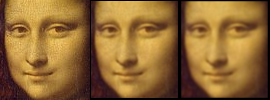

In [182]:
blur_kernel = np.array([[1,2,1],[2,4,2],[1,2,1]])
blur_kernel = blur_kernel/blur_kernel.sum()

lisa_blured = apply_kernel(lisa_face_copy, blur_kernel)
lisa_blured2x = apply_kernel(lisa_blured, blur_kernel)
Image.fromarray(np.concatenate((lisa_face_copy, lisa_blured, lisa_blured2x), axis=1))

### Outline filter

Centre 8, neighbours −1: where all pixels are equal the sum is 0 (black); where the centre differs from its surroundings the result is large - only **edges** remain.

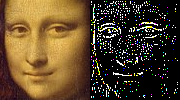

In [183]:
outline_kernel = np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]])/64
Image.fromarray(np.concatenate((lisa_face_copy, apply_kernel(lisa_face_copy, outline_kernel)), axis=1))

### YOUR TURN 5: kernels

1. Apply the **sharpen** kernel `[[0, -1, 0], [-1, 5, -1], [0, -1, 0]]` to the face and show original and result side by side. (Weights sum to 1 - no division needed.)
2. Apply the **horizontal edge** kernel `[[-1, -2, -1], [0, 0, 0], [1, 2, 1]] / 8` (a *Sobel* filter) to the grayscale face. Which edges does it find - horizontal or vertical ones? Two hints: the function expects 3 dimensions, so add a channel axis with `face_gray[:, :, np.newaxis]`; and the result can be **negative**, so convert the input to `float` first, then take `np.abs`, `np.clip` and `.astype(np.uint8)` as in the brightness example.
3. Blur the face **three** times in a loop and show the result.

In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
Image.fromarray(np.concatenate((lisa_face_copy, apply_kernel(lisa_face_copy, sharpen)), axis=1))

In [ ]:
# 2. horizontal edges (changes from top to bottom)
sobel_h = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]) / 8
edges = apply_kernel(face_gray.astype(float)[:, :, np.newaxis], sobel_h)     # float: negative values allowed
edges = np.clip(np.abs(edges[:, :, 0]) * 4, 0, 255).astype(np.uint8)         # * 4 only to make them brighter
Image.fromarray(np.concatenate((face_gray, edges), axis=1))

In [ ]:
# 3.
result = lisa_face_copy
for i in range(3):
    result = apply_kernel(result, blur_kernel)
Image.fromarray(result)

## Where this leads

* **Video** = images + time: a 4D array `(frames, rows, columns, 3)` - see Dmitry Pavlyuk's `Numpy_for_Video.ipynb` in the week 4 folder (the cheetah clip)
* **Computer vision**: OpenCV and scikit-image do today's operations in C, on whole videos
* **Deep learning**: a convolutional neural network is a stack of learned kernels - block 8 touches machine learning with scikit-learn
* Next block (5): **pandas** - tables with column names, the tool for most of your project work

## Summary

* an image is a 3D `uint8` array `(rows, columns, 3)`: `np.asarray(Image.open(...)).copy()` in, `Image.fromarray(arr)` out
* a pixel = three numbers 0-255 (R, G, B); grayscale = one number; `axis=2` is the colour axis
* **crop** = slice rows and columns; a slice is a **view** - copy before changing
* `[::-1]` flips rows, `[:, ::-1]` mirrors, `np.transpose(arr, (1, 0, 2))` / `np.rot90` rotates; `np.concatenate(..., axis=1)` puts pictures side by side
* channels: keep one (`[:, :, [1, 2]] = 0`), re-order (`[:, :, (2, 1, 0)]`), invert (`255 - arr`), posterise (`// 32 * 32`)
* **`uint8` wraps around** - convert to `int` / `float`, compute, `np.clip(0, 255)`, back to `uint8`
* grayscale: `mean(axis=2)`, luminosity `arr @ [0.299, 0.587, 0.114]`, lightness `(max + min) / 2`; a mask on it = a black-and-white image
* **kernels**: blur (positive weights, sum 1), outline / sharpen / Sobel (negative neighbours) - three nested loops over a 3×3 window
* `Image.fromarray(arr).save("file.png")`; watch for 4-channel PNGs
* **Lab 4, exercise 11** = today's operations on an image of your choice

# Thank you